[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/06_visualization_yt_and_zarr.ipynb)

# Cloud-Native OME-Zarr, Out-of-Core `yt` Plotfiles & ML Datasets

Modern synchrotron X-ray CT beamlines and 3D FIB-SEM instruments routinely produce multi-gigabyte tomograms stored in chunked [OME-NGFF / OME-Zarr](https://ngff.openmicroscopy.org/0.4/) archives, while distributed AMReX solver runs export multi-patch `HyperCLaw-V1.1` plotfiles for out-of-core post-processing.

This tutorial demonstrates three ecosystem workflows in OpenImpala:
1. Reading and writing chunked **OME-NGFF v0.4 Zarr** volumes with physical voxel-scale metadata (`dz, dy, dx`).
2. Writing **AMReX plotfiles** directly from `oi.tortuosity(..., write_plotfile=True)` and `oi.effective_diffusivity(..., write_plotfile=True)` and slicing 3D fields lazily with [`yt`](https://yt-project.org/).
3. Generating labelled 3D porous-media training archives for **ML transport surrogates** with `oi.synthetic.generate_ml_dataset()`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q "openimpala[zarr,viz]" 

In [2]:
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yt
import zarr

import openimpala as oi

yt.set_log_level(40)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. Cloud-Native OME-NGFF v0.4 Zarr Volumes

OpenImpala writes and reads OME-NGFF v0.4 `multiscales` metadata (`axes: [z, y, x]` and `coordinateTransformations` physical voxel scale) so physical units propagate automatically from storage into PDE solves without manual re-specification:

In [3]:
workdir = tempfile.TemporaryDirectory()
tmp_root = Path(workdir.name)

vol = oi.datasets.fetch_example("two_phase_cubic")
zarr_path = oi.write_zarr_volume(
    tmp_root / "electrode_fibsem.zarr",
    vol,
    voxel_size=(0.08, 0.05, 0.05),  # (dz, dy, dx) in micrometres
    chunks=(32, 32, 32),
    unit="micrometer",
)

root_grp = zarr.open_group(str(zarr_path), mode="r")
print(json.dumps(dict(root_grp.attrs), indent=2))

{
  "multiscales": [
    {
      "version": "0.4",
      "name": "volume",
      "axes": [
        {
          "name": "z",
          "type": "space",
          "unit": "micrometer"
        },
        {
          "name": "y",
          "type": "space",
          "unit": "micrometer"
        },
        {
          "name": "x",
          "type": "space",
          "unit": "micrometer"
        }
      ],
      "datasets": [
        {
          "path": "0",
          "coordinateTransformations": [
            {
              "type": "scale",
              "scale": [
                0.08,
                0.05,
                0.05
              ]
            }
          ]
        }
      ]
    }
  ]
}

Load the `.zarr` store into a `VoxelImage` (or pass `zarr_path` directly to any solver—OpenImpala reads the OME-NGFF `scale` transform automatically):

In [4]:
img_zarr = oi.VoxelImage.from_zarr(zarr_path)
ssa_phys = oi.specific_surface_area(zarr_path, phase_a=1, phase_b=0)
print(f"Loaded shape={img_zarr.shape}, voxel_size (dz, dy, dx)={img_zarr.voxel_size} um")
ssa_phys

Loaded shape=(64, 64, 64), voxel_size (dz, dy, dx)=(0.08, 0.05, 0.05) um

Metric,Value
SSA (raw),1.009591e+01
SSA (2/3 Cauchy–Crofton),6.730607e+00
SSA (voxel⁻¹),0.576878
"Interfacial faces (x, y, z)","151,225 (50,137, 50,699, 50,389)"
Evaluated voxels,"262,144"


## 2. Out-of-Core AMReX Plotfiles & Lazy Slicing with `yt`

On billion-voxel HPC domains, gathering a dense `float64` 3D field onto rank 0 is impractical. Setting `write_plotfile=True` writes native BoxLib `HyperCLaw-V1.1` plotfile directories (`tortuosity_mlmg_<idir>` and `effdiff_chi_dir<idir>`) that `yt` slices lazily from disk:

In [5]:
plt_root = tmp_root / "amrex_plotfiles"
tau_z = oi.tortuosity(
    zarr_path,
    phase=1,
    direction="z",
    write_plotfile=True,
    results_path=str(plt_root),
)
deff = oi.effective_diffusivity(
    zarr_path,
    phase=1,
    write_plotfile=True,
    results_path=str(plt_root),
)
print("Tortuosity plotfile:", Path(tau_z.plotfile_path).name)
print("Homogenisation plotfiles:", {k: Path(v).name for k, v in deff.plotfile_paths.items()})
deff

Tortuosity plotfile: tortuosity_mlmg_2
Homogenisation plotfiles: {'x': 'effdiff_chi_dir0', 'y': 'effdiff_chi_dir1', 'z': 'effdiff_chi_dir2'}

Component,Value
D_xx,9.952407e-02
D_yy,9.639318e-02
D_zz,1.573245e-01
D_xy,-1.003181e-04
D_xz,2.959331e-03
D_yz,-4.141344e-04
Active VF,0.399326


Inspect the plotfile datasets with `yt.load()` and extract fixed-resolution 2D mid-plane slices ($y = L_y / 2$) of both the flow-through potential $\phi$ and the periodic homogenisation corrector $\chi_z$:

Tortuosity fields: [('boxlib', 'active_mask'), ('boxlib', 'phase_id'), ('boxlib', 'solution_potential')]
Corrector fields:  [('boxlib', 'active_mask_from_solver'), ('boxlib', 'chi_k')]

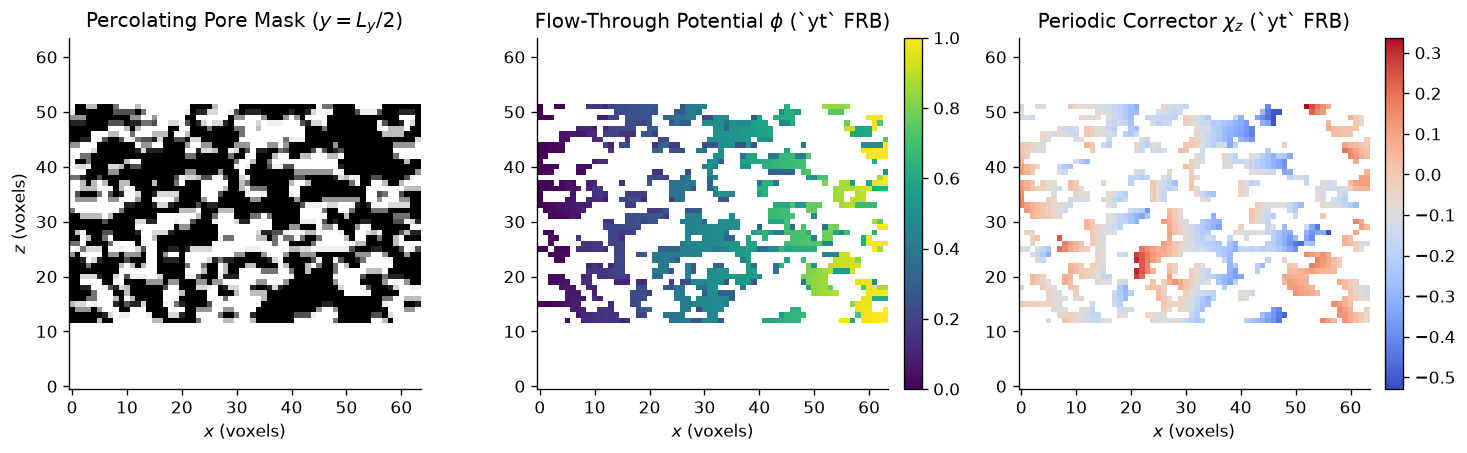

In [6]:
ds_tau = yt.load(tau_z.plotfile_path)
ds_chi = yt.load(deff.plotfile_paths["z"])
print("Tortuosity fields:", ds_tau.field_list)
print("Corrector fields: ", ds_chi.field_list)

nx, ny, nz = [int(x) for x in ds_tau.domain_dimensions]
slc_tau = ds_tau.slice("y", ds_tau.domain_center[1])
frb_tau = slc_tau.to_frb(width=ds_tau.domain_width[2], resolution=(nz, nx))

slc_chi = ds_chi.slice("y", ds_chi.domain_center[1])
frb_chi = slc_chi.to_frb(width=ds_chi.domain_width[2], resolution=(nz, nx))

phi_2d = np.array(frb_tau[("boxlib", "solution_potential")])
mask_2d = np.array(frb_tau[("boxlib", "active_mask")])
chi_2d = np.array(frb_chi[("boxlib", "chi_k")])
chi_mask_2d = np.array(frb_chi[("boxlib", "active_mask_from_solver")])

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))

axes[0].imshow(mask_2d, origin="lower", cmap="Greys_r")
axes[0].set_title("Percolating Pore Mask ($y = L_y/2$)")
axes[0].set_xlabel("$x$ (voxels)")
axes[0].set_ylabel("$z$ (voxels)")

im1 = axes[1].imshow(np.where(mask_2d > 0.5, phi_2d, np.nan), origin="lower", cmap="viridis", vmin=0.0, vmax=1.0)
axes[1].set_title(r"Flow-Through Potential $\phi$ (`yt` FRB)")
axes[1].set_xlabel("$x$ (voxels)")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(np.where(chi_mask_2d > 0.5, chi_2d, np.nan), origin="lower", cmap="coolwarm")
axes[2].set_title(r"Periodic Corrector $\chi_z$ (`yt` FRB)")
axes[2].set_xlabel("$x$ (voxels)")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

fig.tight_layout()

## 3. High-Throughput Synthetic Datasets for 3D ML Surrogates

`openimpala.synthetic` generates procedural 3D porous media (`gaussian_blobs`, `overlapping_spheres`, and `multiphase_electrode`) and pairs them with exact PDE labels in `.npz`, `.h5`, or `.zarr` archives for training 3D CNN / Fourier neural operator surrogates:

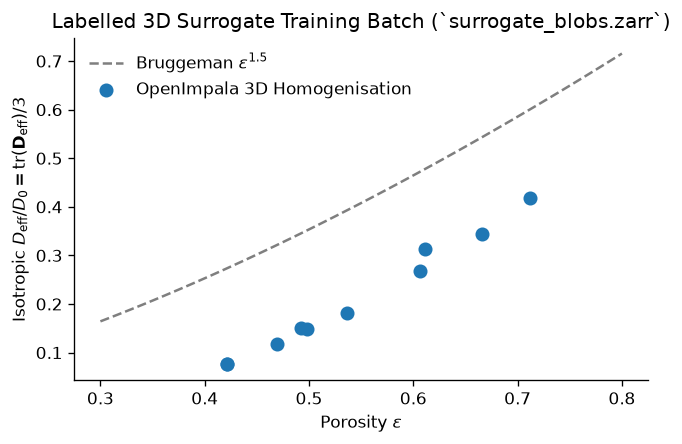

In [7]:
ml_store = tmp_root / "surrogate_blobs.zarr"
dataset = oi.synthetic.generate_ml_dataset(
    ml_store,
    n_samples=10,
    shape=(24, 24, 24),
    generator="blobs",
    porosity_range=(0.35, 0.75),
    seed=2026,
)

eps = dataset["porosity"]
deff_iso = np.trace(dataset["deff_tensor"], axis1=1, axis2=2) / 3.0
eps_curve = np.linspace(0.30, 0.80, 100)

fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.plot(eps_curve, eps_curve ** 1.5, "--", color="tab:gray", label=r"Bruggeman $\varepsilon^{1.5}$")
ax.scatter(eps, deff_iso, s=55, color="tab:blue", zorder=3, label="OpenImpala 3D Homogenisation")
ax.set_xlabel(r"Porosity $\varepsilon$")
ax.set_ylabel(r"Isotropic $D_{\mathrm{eff}} / D_0 = \mathrm{tr}(\mathbf{D}_{\mathrm{eff}})/3$")
ax.set_title("Labelled 3D Surrogate Training Batch (`surrogate_blobs.zarr`)")
ax.legend(frameon=False)
fig.tight_layout()

workdir.cleanup()

## References

1. J. Moore *et al.*, *OME-NGFF: a next-generation file format for expanding bioimaging data-access strategies*, Nat. Methods **18**, 1496–1498 (2021).
2. M. J. Turk *et al.*, *yt: A Multi-code Analysis Toolkit for Astrophysical Simulation Data*, Astrophys. J. Suppl. Ser. **192**, 9 (2011).
3. W. Zhang *et al.*, *AMReX: a framework for block-structured adaptive mesh refinement*, J. Open Source Softw. **4**(37), 1370 (2019).